In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving car_price_prediction_.csv to car_price_prediction_.csv


In [ ]:
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (2500, 10)


,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 2500
Number of columns: 10

Column names:
['Car ID', 'Brand', 'Year', 'Engine Size', 'Fuel Type', 'Transmission', 'Mileage', 'Condition', 'Price', 'Model']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   object 
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   object 
 5   Transmission  2500 non-null   object 
 6   Mileage       2500 non-null   int64  
 7   Condition     2500 non-null   object 
 8   Price         2500 non-null   float64
 9   Model         2500 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 195.4+ KB


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64


In [ ]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [ ]:
df.describe()

,Car ID,Year,Engine Size,Mileage,Price
count,2500.00000,2500.0000,2500.000000,2500.000000,2500.000000
mean,1250.50000,2011.6268,3.465240,149749.844800,52638.022532
std,721.83216,6.9917,1.432053,87919.952034,27295.833455
min,1.00000,2000.0000,1.000000,15.000000,5011.270000
25%,625.75000,2005.0000,2.200000,71831.500000,28908.485000
50%,1250.50000,2012.0000,3.400000,149085.000000,53485.240000
75%,1875.25000,2018.0000,4.700000,225990.500000,75838.532500
max,2500.00000,2023.0000,6.000000,299967.000000,99982.590000


In [ ]:
# Step 9: Define features and target

X = df.drop(columns=['Price', 'Car ID'])
y = df['Price']

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Brand', 'Year', 'Engine Size', 'Fuel Type', 'Transmission', 'Mileage', 'Condition', 'Model']

Target:
Price


In [ ]:
# Step 10: Identify categorical and numerical columns

categorical_columns = X.select_dtypes(include='object').columns.tolist()
numerical_columns = X.select_dtypes(exclude='object').columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['Brand', 'Fuel Type', 'Transmission', 'Condition', 'Model']

Numerical columns:
['Year', 'Engine Size', 'Mileage']


In [ ]:
# Step 11: Convert categorical data into numerical data

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
)

print("Encoded feature shape:", X.shape)
print("\nEncoded columns:")
print(X.columns.tolist())

Encoded feature shape: (2500, 42)

Encoded columns:
['Year', 'Engine Size', 'Mileage', 'Brand_BMW', 'Brand_Ford', 'Brand_Honda', 'Brand_Mercedes', 'Brand_Tesla', 'Brand_Toyota', 'Fuel Type_Electric', 'Fuel Type_Hybrid', 'Fuel Type_Petrol', 'Transmission_Manual', 'Condition_New', 'Condition_Used', 'Model_5 Series', 'Model_A3', 'Model_A4', 'Model_Accord', 'Model_C-Class', 'Model_CR-V', 'Model_Camry', 'Model_Civic', 'Model_Corolla', 'Model_E-Class', 'Model_Explorer', 'Model_Fiesta', 'Model_Fit', 'Model_Focus', 'Model_GLA', 'Model_GLC', 'Model_Model 3', 'Model_Model S', 'Model_Model X', 'Model_Model Y', 'Model_Mustang', 'Model_Prius', 'Model_Q5', 'Model_Q7', 'Model_RAV4', 'Model_X3', 'Model_X5']


In [ ]:
# Step 12: Check missing values after encoding

print("Missing values in X:")
print(X.isnull().sum().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

Missing values in X:
0

Missing values in y:
0


In [ ]:
# Step 13: Ensure all features are numeric

X = X.astype(float)

print(X.dtypes.value_counts())

float64    42
Name: count, dtype: int64


In [ ]:
# Step 14: Split dataset into training and testing data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Total samples: 2500
Training samples: 2000
Testing samples: 500


In [ ]:
# Step 15: Train Linear Regression model

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
# Step 16: Predict car prices

y_pred_linear = linear_model.predict(X_test)

print("First 10 predicted prices:")
print(y_pred_linear[:10])

First 10 predicted prices:
[55824.64173003 50892.64866668 53979.60134944 53650.0954578
 52089.32009052 51733.75539175 49239.89989157 53813.84499759
 53621.87307563 52667.72970012]


In [ ]:
# Step 17: Evaluate Linear Regression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("--------------------------------")
print("MAE      :", mae_linear)
print("RMSE     :", rmse_linear)
print("R2 Score :", r2_linear)

Linear Regression Performance
--------------------------------
MAE      : 23877.143118813055
RMSE     : 27794.413123934606
R2 Score : -0.019768995768101316


In [ ]:
# Step 18: Train Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Step 19: Predict using Random Forest

y_pred_rf = rf_model.predict(X_test)

print("First 10 Random Forest predictions:")
print(y_pred_rf[:10])

First 10 Random Forest predictions:
[64257.44015 40619.43115 49292.1872  50793.8796  48989.592   42791.8269
 55256.6879  46115.41085 56153.72785 55994.99865]


In [ ]:
# Step 20: Evaluate Random Forest

mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------")
print("MAE      :", mae_rf)
print("RMSE     :", rmse_rf)
print("R2 Score :", r2_rf)

Random Forest Performance
--------------------------
MAE      : 24689.843011199995
RMSE     : 28575.132507513594
R2 Score : -0.07786232734296439


In [ ]:
# Step 21: Compare machine learning models

results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        mae_linear,
        mae_rf
    ],
    'RMSE': [
        rmse_linear,
        rmse_rf
    ],
    'R2 Score': [
        r2_linear,
        r2_rf
    ]
})

display(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,23877.143119,27794.413124,-0.019769
1,Random Forest,24689.843011,28575.132508,-0.077862


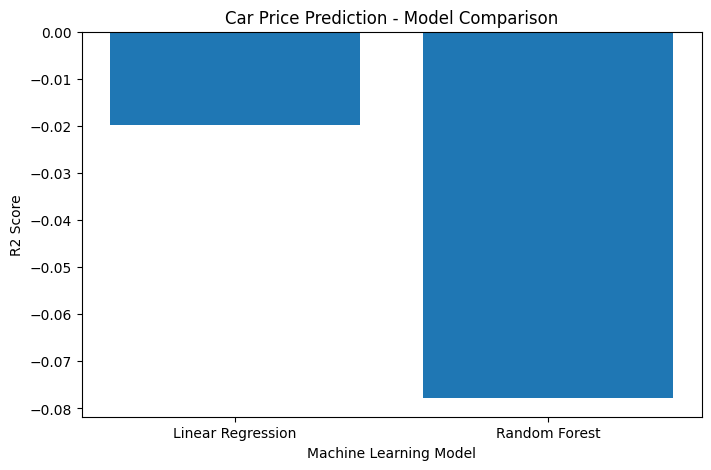

In [ ]:
# Step 22: Compare R2 scores

plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['R2 Score']
)

plt.xlabel('Machine Learning Model')
plt.ylabel('R2 Score')
plt.title('Car Price Prediction - Model Comparison')

plt.show()

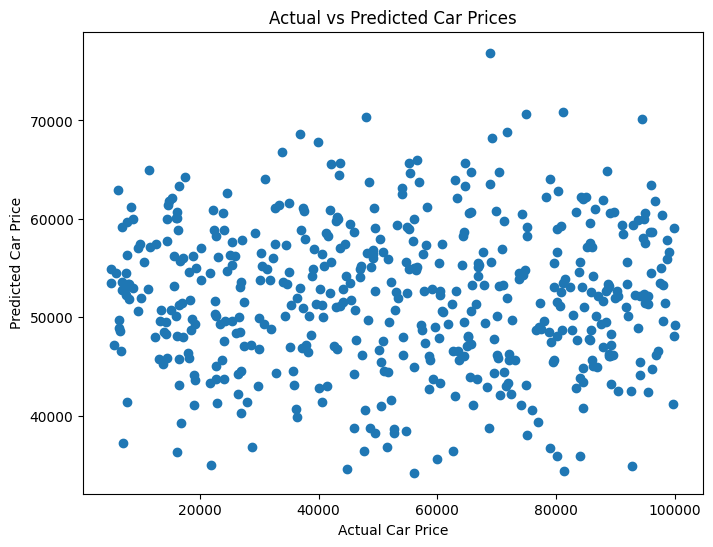

In [ ]:
# Step 23: Actual vs Predicted Prices

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf
)

plt.xlabel('Actual Car Price')
plt.ylabel('Predicted Car Price')
plt.title('Actual vs Predicted Car Prices')

plt.show()

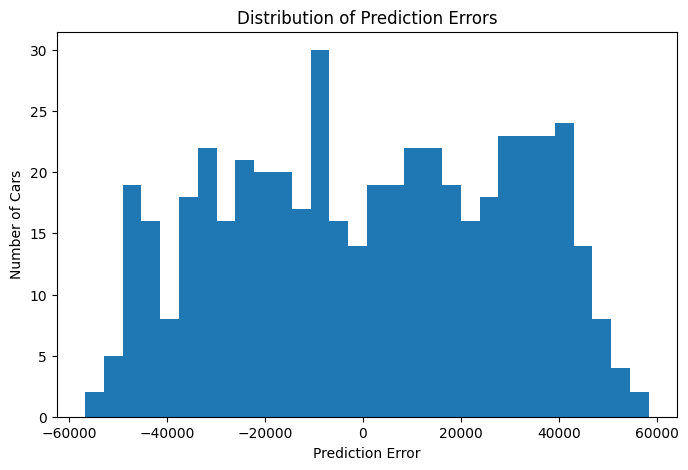

In [ ]:
# Step 24: Prediction errors

errors = y_test - y_pred_rf

plt.figure(figsize=(8, 5))

plt.hist(errors, bins=30)

plt.xlabel('Prediction Error')
plt.ylabel('Number of Cars')
plt.title('Distribution of Prediction Errors')

plt.show()

In [ ]:
# Step 25: Feature importance

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
2,Mileage,0.250015
1,Engine Size,0.177331
0,Year,0.140519
12,Transmission_Manual,0.026721
13,Condition_New,0.023311
14,Condition_Used,0.022781
10,Fuel Type_Hybrid,0.022526
11,Fuel Type_Petrol,0.022306
9,Fuel Type_Electric,0.021068
3,Brand_BMW,0.015228


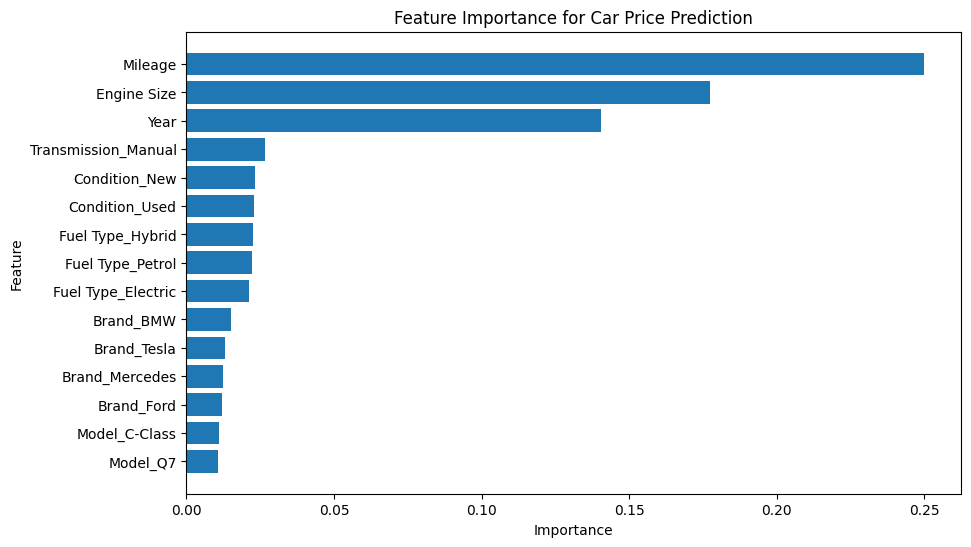

In [ ]:
# Step 26: Feature importance visualization

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance for Car Price Prediction')

plt.gca().invert_yaxis()

plt.show()

In [ ]:
# Step 27: Actual vs predicted price table

prediction_table = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_rf
})

prediction_table['Difference'] = (
    prediction_table['Actual Price']
    - prediction_table['Predicted Price']
)

display(prediction_table.head(15))

,Actual Price,Predicted Price,Difference
0,17494.90,64257.44015,-46762.54015
1,75919.94,40619.43115,35300.50885
2,87474.10,49292.18720,38181.91280
3,13522.58,50793.87960,-37271.29960
4,77070.57,48989.59200,28080.97800
5,40085.49,42791.82690,-2706.33690
6,47196.40,55256.68790,-8060.28790
7,58558.94,46115.41085,12443.52915
8,23029.74,56153.72785,-33123.98785
9,32351.06,55994.99865,-23643.93865


In [ ]:
print(X.columns.tolist())

['Year', 'Engine Size', 'Mileage', 'Brand_BMW', 'Brand_Ford', 'Brand_Honda', 'Brand_Mercedes', 'Brand_Tesla', 'Brand_Toyota', 'Fuel Type_Electric', 'Fuel Type_Hybrid', 'Fuel Type_Petrol', 'Transmission_Manual', 'Condition_New', 'Condition_Used', 'Model_5 Series', 'Model_A3', 'Model_A4', 'Model_Accord', 'Model_C-Class', 'Model_CR-V', 'Model_Camry', 'Model_Civic', 'Model_Corolla', 'Model_E-Class', 'Model_Explorer', 'Model_Fiesta', 'Model_Fit', 'Model_Focus', 'Model_GLA', 'Model_GLC', 'Model_Model 3', 'Model_Model S', 'Model_Model X', 'Model_Model Y', 'Model_Mustang', 'Model_Prius', 'Model_Q5', 'Model_Q7', 'Model_RAV4', 'Model_X3', 'Model_X5']


In [ ]:
# Step 28: Create a sample car from an existing test row

sample_car = X_test.iloc[[0]]

predicted_price = rf_model.predict(sample_car)[0]

actual_price = y_test.iloc[0]

print("Actual Price    :", actual_price)
print("Predicted Price :", predicted_price)

Actual Price    : 17494.9
Predicted Price : 64257.440149999966


In [ ]:
# Step 29: Save trained model

import joblib

joblib.dump(rf_model, 'car_price_prediction_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Step 30: Predict price for a new car

print("🚗 CAR PRICE PREDICTION")
print("=" * 40)

brand = input("Enter Brand: ")
year = int(input("Enter Year: "))
engine_size = float(input("Enter Engine Size: "))
fuel_type = input("Enter Fuel Type: ")
transmission = input("Enter Transmission: ")
mileage = float(input("Enter Mileage: "))
condition = input("Enter Condition: ")
model = input("Enter Model: ")

# Create input dataframe
new_car = pd.DataFrame({
    'Brand': [brand],
    'Year': [year],
    'Engine Size': [engine_size],
    'Fuel Type': [fuel_type],
    'Transmission': [transmission],
    'Mileage': [mileage],
    'Condition': [condition],
    'Model': [model]
})

# Apply the same encoding used during training
new_car = pd.get_dummies(
    new_car,
    columns=['Brand', 'Fuel Type', 'Transmission', 'Condition', 'Model'],
    drop_first=True
)

# Make sure new_car has exactly the same columns as X
new_car = new_car.reindex(columns=X.columns, fill_value=0)

# Predict
predicted_price = rf_model.predict(new_car)[0]

print("\n" + "=" * 40)
print("🚗 PREDICTED CAR PRICE")
print("=" * 40)
print(f"₹{predicted_price:,.2f}")

🚗 CAR PRICE PREDICTION
Enter Brand: tesla
Enter Year: 2022
Enter Engine Size: 3.0
Enter Fuel Type: petrol
Enter Transmission: automatic
Enter Mileage: 30000
Enter Condition: good
Enter Model: model S

🚗 PREDICTED CAR PRICE
₹53,623.67
